# Error Analysis of Model Predictions

This notebook analyzes the model's incorrect predictions from both qualitative and quantitative perspectives. We first identify and visualize misclassified images, then prepare a table for manual error annotation, and finally evaluate prediction confidence and calibration.

## 1. Load and Inspect Prediction Results

This section loads the model prediction results and checks the dataset structure. We verify the number of predictions and the available columns before performing the error analysis.

In [1]:
import pandas as pd
from pathlib import Path

# Load predictions
csv_path = Path("antler_test_predictions.csv")

df = pd.read_csv(csv_path)

print("Total predictions:", len(df))
print("Columns:", df.columns.tolist())

display(df.head())


Total predictions: 681
Columns: ['row_id', 'filename', 'year', 'month', 'bbox_origin_x', 'bbox_origin_y', 'bbox_width', 'bbox_height', 'bbox_confidence', 'antler_status', 'age_status', 'head_visibility', 'status', 'fallback', 'attempts', 'finish_reason', 'error', 'y_antler', 'path', 'file_exists', 'prob_antlered', 'predicted_class', 'predicted_label', 'correct', 'decision_rule']


,row_id,filename,year,month,bbox_origin_x,bbox_origin_y,bbox_width,bbox_height,bbox_confidence,antler_status,...,finish_reason,error,y_antler,path,file_exists,prob_antlered,predicted_class,predicted_label,correct,decision_rule
0,19,SSWI000000029324421B.jpg,2023,1,0.1543,0.4333,0.4756,0.5625,0.985,ANTLERLESS,...,stop,NaN,0,X:\aanand37\Manuscript\Snapshot Wisconsin\data...,True,0.260201,0,Antlerless,True,argmax
1,23,SSWI000000019560477A.jpg,2020,9,0.4668,0.6799,0.2425,0.3166,0.974,ANTLERLESS,...,stop,NaN,0,X:\aanand37\Manuscript\Snapshot Wisconsin\data...,True,0.082920,0,Antlerless,True,argmax
2,27,SSWI000000014292195B.jpg,2019,7,0.0000,0.4441,0.2637,0.4683,0.969,ANTLERLESS,...,stop,NaN,0,X:\aanand37\Manuscript\Snapshot Wisconsin\data...,True,0.052279,0,Antlerless,True,argmax
3,28,SSWI000000032405899B.jpg,2023,8,0.7218,0.4516,0.2781,0.5483,0.974,ANTLERLESS,...,stop,NaN,0,X:\aanand37\Manuscript\Snapshot Wisconsin\data...,True,0.059102,0,Antlerless,True,argmax
4,32,SSWI000000020664352A.jpg,2020,6,0.4612,0.4883,0.2287,0.3458,0.967,ANTLERLESS,...,stop,NaN,0,X:\aanand37\Manuscript\Snapshot Wisconsin\data...,True,0.036804,0,Antlerless,True,argmax


### Identify Incorrect Predictions

We identify all incorrectly classified samples using the `correct` column. These samples will be used for visual inspection and manual error annotation.

In [2]:
# Check prediction-related columns
print([col for col in df.columns
       if col in ["correct", "y_antler",
                  "predicted_class", "prob_antlered"]])

# Extract incorrect predictions
errors = df[df["correct"] == False].copy()

print("Total errors:", len(errors))

# Show first 10 incorrect predictions
display(errors.head(10))

['y_antler', 'prob_antlered', 'predicted_class', 'correct']
Total errors: 75


,row_id,filename,year,month,bbox_origin_x,bbox_origin_y,bbox_width,bbox_height,bbox_confidence,antler_status,...,finish_reason,error,y_antler,path,file_exists,prob_antlered,predicted_class,predicted_label,correct,decision_rule
21,127,SSWI000000029352361A.jpg,2022,8,0.43490,0.7941,0.23740,0.2033,0.965,ANTLERLESS,...,stop,NaN,0,X:\aanand37\Manuscript\Snapshot Wisconsin\data...,True,0.600320,1,Antlered,False,argmax
37,270,SSWI000000027089989C.jpg,2022,7,0.63930,0.5233,0.12680,0.1899,0.958,ANTLERLESS,...,stop,NaN,0,X:\aanand37\Manuscript\Snapshot Wisconsin\data...,True,0.535129,1,Antlered,False,argmax
42,347,SSWI000000024701514C.jpg,2021,11,0.33430,0.4141,0.55750,0.4733,0.975,ANTLERLESS,...,stop,NaN,0,X:\aanand37\Manuscript\Snapshot Wisconsin\data...,True,0.745352,1,Antlered,False,argmax
78,589,SSWI000000020664313C.jpg,2020,6,0.03499,0.3666,0.70930,0.6299,0.976,ANTLERLESS,...,stop,NaN,0,X:\aanand37\Manuscript\Snapshot Wisconsin\data...,True,0.853608,1,Antlered,False,argmax
110,804,SSWI000000014292584A.jpg,2019,7,0.50490,0.5858,0.49500,0.3283,0.953,ANTLERLESS,...,stop,NaN,0,X:\aanand37\Manuscript\Snapshot Wisconsin\data...,True,0.604260,1,Antlered,False,argmax
122,885,SSWI000000009745082C.jpg,2018,6,0.19180,0.6708,0.35310,0.2891,0.955,ANTLERLESS,...,stop,NaN,0,X:\aanand37\Manuscript\Snapshot Wisconsin\data...,True,0.815085,1,Antlered,False,argmax
134,981,SSWI000000020365082A.jpg,2019,12,0.37430,0.6541,0.09562,0.2058,0.963,ANTLERED,...,stop,NaN,1,X:\aanand37\Manuscript\Snapshot Wisconsin\data...,True,0.094260,0,Antlerless,False,argmax
135,982,SSWI000000024641077C.jpg,2021,11,0.68620,0.2875,0.28560,0.4033,0.952,ANTLERED,...,stop,NaN,1,X:\aanand37\Manuscript\Snapshot Wisconsin\data...,True,0.081739,0,Antlerless,False,argmax
141,1040,SSWI000000011468024A.jpg,2019,1,0.25750,0.4833,0.27250,0.3133,0.971,ANTLERED,...,stop,NaN,1,X:\aanand37\Manuscript\Snapshot Wisconsin\data...,True,0.116764,0,Antlerless,False,argmax
151,1100,SSWI000000012376030B.jpg,2018,11,0.35740,0.4483,0.17240,0.3183,0.959,ANTLERED,...,stop,NaN,1,X:\aanand37\Manuscript\Snapshot Wisconsin\data...,True,0.245266,0,Antlerless,False,argmax


### Inspect Error Records

Before locating the original images, we inspect the filename and path information associated with an incorrect prediction.

In [3]:
print("Available columns:")
print(df.columns.tolist())

print("\nFirst error image:")
print(errors.iloc[0]["filename"])

if "path" in errors.columns:
    print("\nOriginal image path:")
    print(errors.iloc[0]["path"])


Available columns:
['row_id', 'filename', 'year', 'month', 'bbox_origin_x', 'bbox_origin_y', 'bbox_width', 'bbox_height', 'bbox_confidence', 'antler_status', 'age_status', 'head_visibility', 'status', 'fallback', 'attempts', 'finish_reason', 'error', 'y_antler', 'path', 'file_exists', 'prob_antlered', 'predicted_class', 'predicted_label', 'correct', 'decision_rule']

First error image:
SSWI000000029352361A.jpg

Original image path:
X:\aanand37\Manuscript\Snapshot Wisconsin\data\Snapshot_WI-Oh_Deer_Photos\Deer\SSWI000000029352361A.jpg


## 2. Locate and Visualize Misclassified Images

The prediction file contains image filenames, but the original images may be stored in a different directory. This step searches the Snapshot project folder to locate the corresponding image files.

In [17]:
from pathlib import Path

# Search the entire Snapshot project
project_dir = Path.cwd().parent

filename = errors.iloc[0]["filename"]

print("Searching in:", project_dir)

matches = list(project_dir.rglob(filename))

print("Matches found:", len(matches))

for path in matches[:5]:
    print("Found:", path)


Searching in: d:\电子教材\UWM\Snapshot
Matches found: 1
Found: d:\电子教材\UWM\Snapshot\Snapshot_WI-Oh_Deer_Photos\Deer\SSWI000000029352361A.jpg


### Visualize Incorrect Predictions

We visualize a subset of incorrectly classified images together with their ground-truth labels, predicted labels, and prediction probabilities. This helps identify common visual patterns among the model errors.

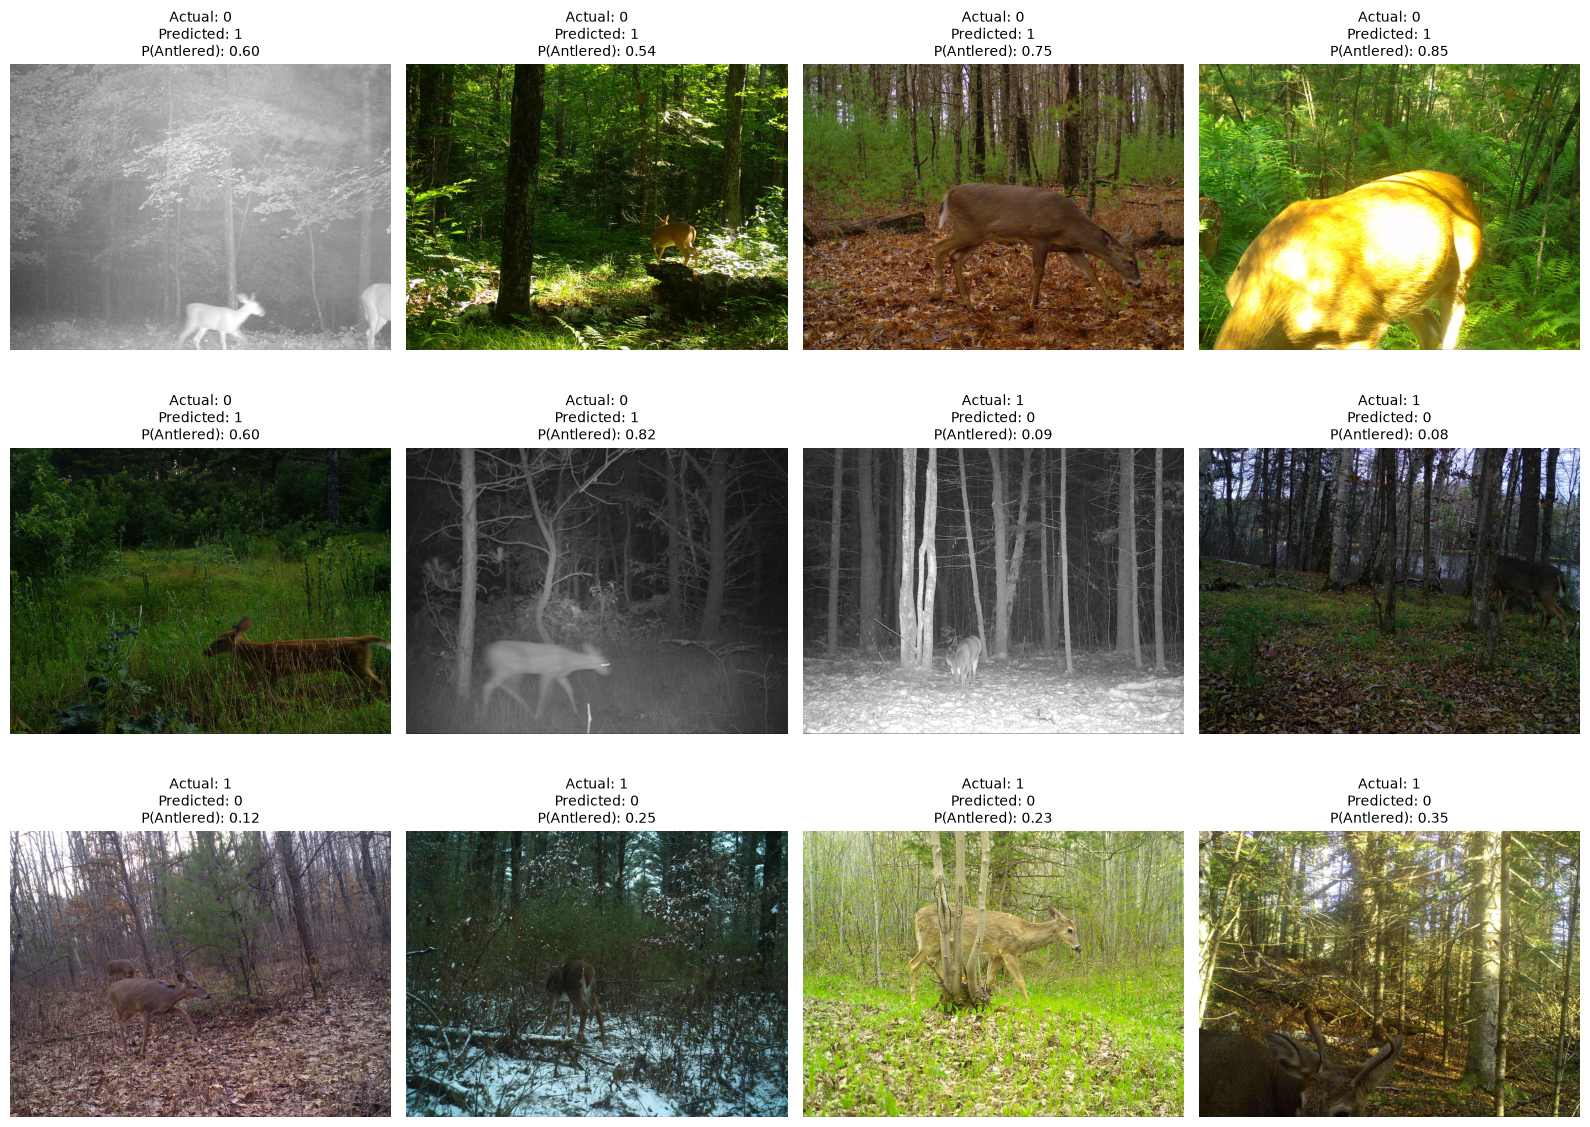

In [9]:

import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

# Search inside the Snapshot project
project_dir = Path.cwd().parent

sample_errors = errors.head(12)

fig, axes = plt.subplots(3, 4, figsize=(16, 12))

for ax, (_, row) in zip(axes.flat, sample_errors.iterrows()):

    filename = row["filename"]

    # Automatically locate image
    matches = list(project_dir.rglob(filename))

    if matches:
        image_path = matches[0]
        img = Image.open(image_path).convert("RGB")

        ax.imshow(img)
        ax.set_title(
            f"Actual: {row['y_antler']}\n"
            f"Predicted: {row['predicted_class']}\n"
            f"P(Antlered): {row['prob_antlered']:.2f}",
            fontsize=10
        )
    else:
        ax.text(
            0.5, 0.5,
            f"Image not found\n{filename}",
            ha="center",
            va="center",
            fontsize=9
        )

    ax.axis("off")

plt.tight_layout()
plt.show()


### Visualize Bounding Boxes

The normalized bounding-box coordinates are overlaid on the misclassified images. This allows us to examine whether the relevant deer head or antler region was visible and whether the model focused on an appropriate image region.

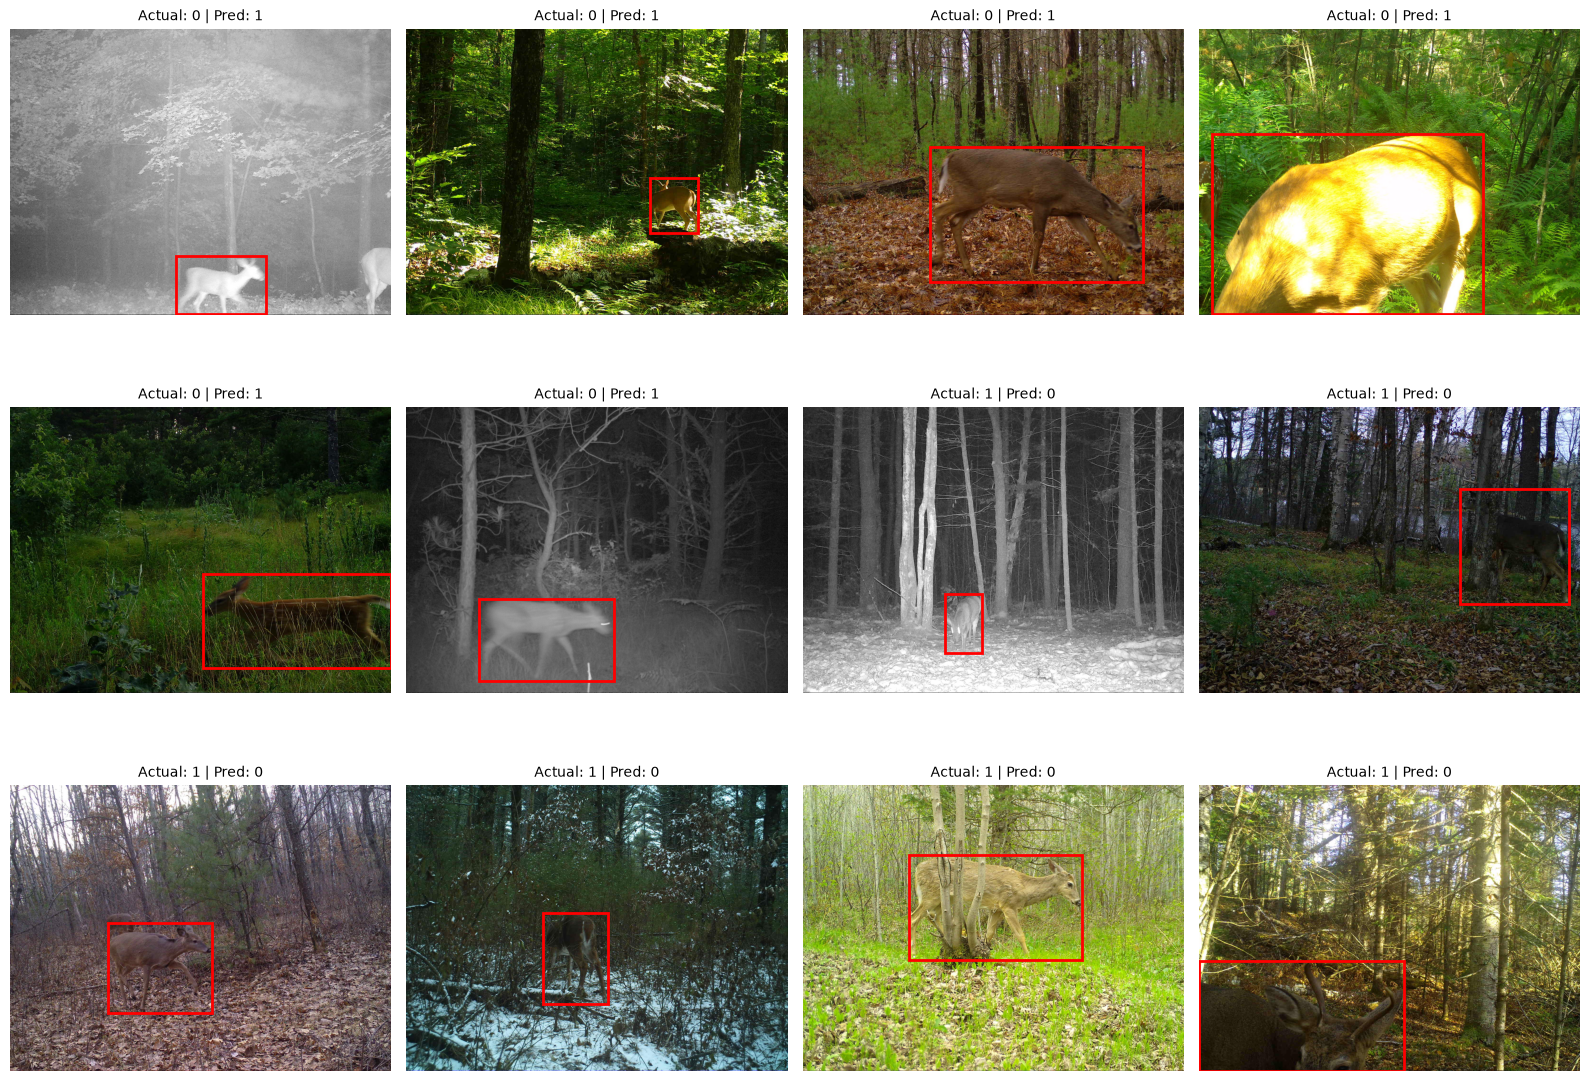

In [10]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from pathlib import Path
import pandas as pd

project_dir = Path.cwd().parent
sample_errors = errors.head(12)

fig, axes = plt.subplots(3, 4, figsize=(16, 12))

for ax, (_, row) in zip(axes.flat, sample_errors.iterrows()):
    matches = list(project_dir.rglob(row["filename"]))

    if not matches:
        ax.set_title("Image not found")
        ax.axis("off")
        continue

    img = Image.open(matches[0]).convert("RGB")
    width, height = img.size
    ax.imshow(img)

    # Normalized bounding box coordinates
    x = float(row["bbox_origin_x"]) * width
    y = float(row["bbox_origin_y"]) * height
    w = float(row["bbox_width"]) * width
    h = float(row["bbox_height"]) * height

    rect = patches.Rectangle(
        (x, y), w, h,
        linewidth=2,
        edgecolor="red",
        facecolor="none"
    )
    ax.add_patch(rect)

    ax.set_title(
        f"Actual: {row['y_antler']} | "
        f"Pred: {row['predicted_class']}",
        fontsize=10
    )
    ax.axis("off")

plt.tight_layout()
plt.show()


## 3. Prepare Manual Error Annotation

To analyze the causes of individual errors, we create an annotation table for the misclassified samples. The table records whether the head and antlers are visible, the likely reason for the error, and additional notes from manual inspection.

In [11]:
import pandas as pd

# Prepare error analysis table
analysis = errors.copy()

analysis["error_type"] = analysis.apply(
    lambda row: "FP" if row["y_antler"] == 0 else "FN",
    axis=1
)

analysis["head_visible"] = ""
analysis["antlers_visible"] = ""
analysis["error_reason"] = ""
analysis["notes"] = ""

# Select columns for manual annotation
analysis = analysis[
    [
        "filename",
        "y_antler",
        "predicted_class",
        "prob_antlered",
        "error_type",
        "head_visible",
        "antlers_visible",
        "error_reason",
        "notes"
    ]
]

analysis.to_csv("error_analysis_annotations.csv", index=False)

print("Total samples:", len(analysis))
display(analysis.head(12))


Total samples: 75


,filename,y_antler,predicted_class,prob_antlered,error_type,head_visible,antlers_visible,error_reason,notes
21,SSWI000000029352361A.jpg,0,1,0.600320,FP,,,,
37,SSWI000000027089989C.jpg,0,1,0.535129,FP,,,,
42,SSWI000000024701514C.jpg,0,1,0.745352,FP,,,,
78,SSWI000000020664313C.jpg,0,1,0.853608,FP,,,,
110,SSWI000000014292584A.jpg,0,1,0.604260,FP,,,,
122,SSWI000000009745082C.jpg,0,1,0.815085,FP,,,,
134,SSWI000000020365082A.jpg,1,0,0.094260,FN,,,,
135,SSWI000000024641077C.jpg,1,0,0.081739,FN,,,,
141,SSWI000000011468024A.jpg,1,0,0.116764,FN,,,,
151,SSWI000000012376030B.jpg,1,0,0.245266,FN,,,,


## 4. Analyze Prediction Confidence and Calibration

This section compares the confidence distributions of correct and incorrect predictions. The goal is to determine whether incorrect predictions tend to have lower confidence, or whether the model sometimes makes highly confident mistakes.

Average confidence:
Correct: 0.905
Incorrect: 0.791


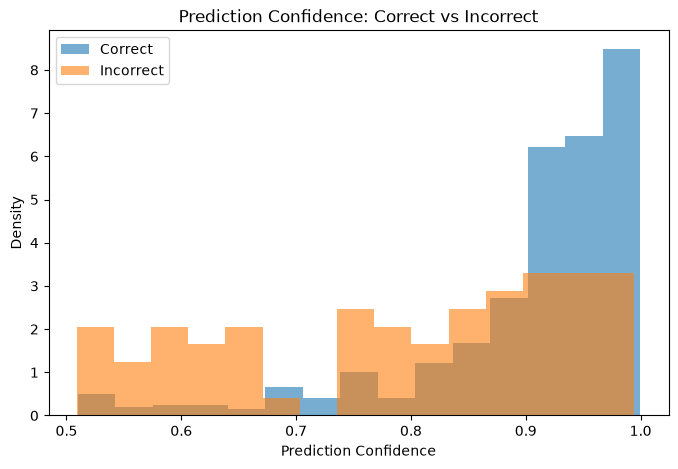

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# Confidence of the predicted class
df["confidence"] = np.maximum(
    df["prob_antlered"],
    1 - df["prob_antlered"]
)

# Correct vs Incorrect predictions
correct = df[df["correct"] == True]
incorrect = df[df["correct"] == False]

print("Average confidence:")
print("Correct:", round(correct["confidence"].mean(), 3))
print("Incorrect:", round(incorrect["confidence"].mean(), 3))

plt.figure(figsize=(8, 5))

plt.hist(correct["confidence"],
         bins=15, alpha=0.6,
         label="Correct", density=True)

plt.hist(incorrect["confidence"],
         bins=15, alpha=0.6,
         label="Incorrect", density=True)

plt.xlabel("Prediction Confidence")
plt.ylabel("Density")
plt.title("Prediction Confidence: Correct vs Incorrect")
plt.legend()
plt.show()


### Evaluate Accuracy Across Confidence Ranges

We divide predictions into confidence bins and calculate the observed accuracy within each bin. The resulting reliability diagram compares the model's reported confidence with its actual accuracy.

,mean_confidence,accuracy,count
confidence_bin,,,
"(0.499, 0.6]",0.548424,0.607143,28
"(0.6, 0.7]",0.648733,0.612903,31
"(0.7, 0.8]",0.752949,0.780000,50
"(0.8, 0.9]",0.860290,0.864000,125
"(0.9, 1.0]",0.955046,0.946309,447


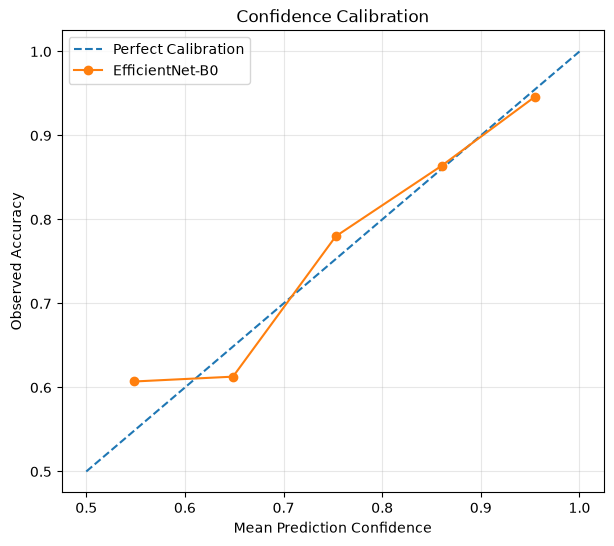

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

# Confidence bins
bins = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

df["confidence_bin"] = pd.cut(
    df["confidence"],
    bins=bins,
    include_lowest=True
)

# Accuracy within each confidence range
calibration = df.groupby(
    "confidence_bin",
    observed=True
).agg(
    mean_confidence=("confidence", "mean"),
    accuracy=("correct", "mean"),
    count=("correct", "size")
)

display(calibration)

# Reliability diagram
plt.figure(figsize=(7, 6))

plt.plot(
    [0.5, 1.0], [0.5, 1.0],
    "--", label="Perfect Calibration"
)

plt.plot(
    calibration["mean_confidence"],
    calibration["accuracy"],
    marker="o",
    label="EfficientNet-B0"
)

plt.xlabel("Mean Prediction Confidence")
plt.ylabel("Observed Accuracy")
plt.title("Confidence Calibration")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### Calculate Expected Calibration Error

Expected Calibration Error (ECE) summarizes the difference between predicted confidence and observed accuracy across confidence bins. A smaller ECE indicates that the model's confidence scores are better aligned with its actual performance.

In [15]:

import numpy as np

ece = (
    calibration["count"]
    / calibration["count"].sum()
    * abs(
        calibration["accuracy"]
        - calibration["mean_confidence"]
    )
).sum()

print(f"Expected Calibration Error: {ece:.4f}")

print("\nCalibration by confidence bin:")
display(calibration)


Expected Calibration Error: 0.0124

Calibration by confidence bin:


,mean_confidence,accuracy,count
confidence_bin,,,
"(0.499, 0.6]",0.548424,0.607143,28
"(0.6, 0.7]",0.648733,0.612903,31
"(0.7, 0.8]",0.752949,0.780000,50
"(0.8, 0.9]",0.860290,0.864000,125
"(0.9, 1.0]",0.955046,0.946309,447


# Summary

This error analysis examined the model from three complementary perspectives:

1. Which samples were misclassified.
2. What visual characteristics may have contributed to the errors.
3. Whether the model's confidence scores were consistent with its actual accuracy.

The image visualizations and manual annotation table support qualitative analysis of error patterns, while the confidence histogram, reliability diagram, and Expected Calibration Error (ECE) provide a quantitative evaluation of prediction reliability.

A well-calibrated model should have confidence values that closely match its observed accuracy. However, calibration alone does not explain why individual images were misclassified, so it should be interpreted together with the visual and manual error analysis.